# Terrain Modification Layer Writers: Write, Read Back, Verify in RAS Mapper

This notebook drives every `RasTerrainModWriter` layer kind on a real terrain, reads the
layers back, writes them into a second terrain, and asks RAS Mapper itself to rasterize both.
The writers store layers the way RAS Mapper saves them in HEC-RAS 6.6 and 7.0.1, so RAS
Mapper applies a written layer exactly as it applies one drawn in its own editor.

- **Writers:** `add_channel_modification`, `add_high_ground_modification`,
  `add_modification_polygon(elevation=...)`, `add_ellipse_modification`, and
  `add_modification_layer`, which writes back a layer returned by `read_layers`.
- **Inputs:** the `BaldEagleCrkMulti2D` example project (`Terrain50`), extracted twice by
  `RasExamples`: an *authored* copy and a *round-trip* copy.
- **Evidence:** `RasTerrain.export_rasmapper_terrain()` runs RAS Mapper's own
  *Export to Single Raster* on a bounded 3,600-ft window, with modifications off and on, for
  each installed release among HEC-RAS 6.6 and 7.0.1. The checks compare pixels exactly.
- **Runtime:** about a minute on Windows with HEC-RAS installed. Writing and reading need only
  `h5py`; the exports need a qualified HEC-RAS installation.
- **Scope:** terrain only. No hydraulic plan is run, and the layer elevations are
  illustrations, not designs. All outputs stay under `working/`.

In [1]:
# =============================================================================
# DEVELOPMENT MODE TOGGLE
# =============================================================================
# True uses this checkout; False uses an installed ras-commander package.

USE_LOCAL_SOURCE = True

import sys
from pathlib import Path

REPO_ROOT = Path.cwd()
if REPO_ROOT.name.lower() == "examples":
    REPO_ROOT = REPO_ROOT.parent

if USE_LOCAL_SOURCE:
    local_path = str(REPO_ROOT)
    if local_path not in sys.path:
        sys.path.insert(0, local_path)
    print("LOCAL SOURCE MODE: Loading from this checkout's ras_commander package")
else:
    print("PIP PACKAGE MODE: Loading installed ras-commander")

LOCAL SOURCE MODE: Loading from this checkout's ras_commander package


In [2]:
import os
import xml.etree.ElementTree as ET

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import rasterio.transform
import shapely
from IPython.display import display
from shapely import affinity
from shapely.geometry import LineString, Point, Polygon

from ras_commander import RasExamples, RasTerrain, get_ras_exe
from ras_commander.fim._terrain_mods import read_layers
from ras_commander.terrain import RasTerrainModWriter

RAS_VERSIONS = ("6.6", "7.0.1")  # releases whose saved layer layout the writers follow
TERRAIN_NAME = "Terrain50"
RASMAP_NAME = "BaldEagleDamBrk.rasmap"

# Bounded export window on the BaldEagleCr 2D area (project feet)
X0, Y0, SIZE = 2041060.0, 346430.0, 3600.0
EXPORT_EXTENT = (X0, Y0, X0 + SIZE, Y0 + SIZE)

RUN_ROOT = Path(
    os.environ.get(
        "RAS_COMMANDER_EXAMPLE_RUN_ROOT",
        REPO_ROOT / "working" / "example_321_terrain_modification_layer_writers",
    )
).resolve()
RUN_ROOT.mkdir(parents=True, exist_ok=True)
EXPORT_DIR = RUN_ROOT / "exports"

def run_path(path):
    '''Return a portable label for an artifact under this notebook's run root.'''
    return str(Path("run") / Path(path).resolve().relative_to(RUN_ROOT))

def site(fx, fy):
    '''Map coordinates at fractions (fx, fy) of the export window.'''
    return (X0 + fx * SIZE, Y0 + fy * SIZE)

installed = [v for v in RAS_VERSIONS if Path(get_ras_exe(v)).is_file()]
print(f"Run root: {RUN_ROOT.name}")
print(f"HEC-RAS releases used for the RAS Mapper exports: {installed or 'none installed'}")

Run root: example_321_terrain_modification_layer_writers
HEC-RAS releases used for the RAS Mapper exports: ['6.6', '7.0.1']


## Extract two copies of the project

The *authored* copy receives layers from the individual writers. The *round-trip* copy starts
from the same unmodified terrain and receives the layers read back from the authored copy.
`RasExamples` extracts both; the shared example cache is not modified.

In [3]:
copies = {}
for label in ("authored", "roundtrip"):
    copies[label] = RasExamples.extract_project(
        "BaldEagleCrkMulti2D", output_path=RUN_ROOT / "projects", suffix=f"321_{label}"
    )

authored, roundtrip = copies["authored"], copies["roundtrip"]
terrain_a = authored / "Terrain" / f"{TERRAIN_NAME}.hdf"
terrain_b = roundtrip / "Terrain" / f"{TERRAIN_NAME}.hdf"
rasmap_a, rasmap_b = authored / RASMAP_NAME, roundtrip / RASMAP_NAME
for path in (terrain_a, terrain_b, rasmap_a, rasmap_b):
    assert path.exists(), path
    print(run_path(path))

2026-11-11 18:35:21 - ras_commander.RasExamples - INFO - Successfully extracted project 'BaldEagleCrkMulti2D' to BaldEagleCrkMulti2D_321_authored


2026-11-11 18:35:22 - ras_commander.RasExamples - INFO - Successfully extracted project 'BaldEagleCrkMulti2D' to BaldEagleCrkMulti2D_321_roundtrip


run\projects\BaldEagleCrkMulti2D_321_authored\Terrain\Terrain50.hdf
run\projects\BaldEagleCrkMulti2D_321_roundtrip\Terrain\Terrain50.hdf
run\projects\BaldEagleCrkMulti2D_321_authored\BaldEagleDamBrk.rasmap
run\projects\BaldEagleCrkMulti2D_321_roundtrip\BaldEagleDamBrk.rasmap


## Write four layers with the individual writers

Each call writes one layer into the terrain HDF (`/Modifications/<name>`) and registers it in
the `.rasmap` under an `ElevationModificationGroup`. RAS Mapper applies HDF modifications only
when the terrain's `.rasmap` layer has that group. Each new layer goes on top (Priority 0),
which wins where layers overlap.

| Layer | Writer | Merge mode | Elevation input |
| --- | --- | --- | --- |
| Pilot Channel | `add_channel_modification` | `take_lower` (Lower Terrain Value) | absolute invert `profile_points`, 548 to 546 ft |
| Training Levee | `add_high_ground_modification` | `take_higher` (Higher Terrain Value) | constant crest `elevation=562` |
| Building Pad | `add_modification_polygon` | `set_value` | constant `elevation=560` |
| Pond and Mound | `add_ellipse_modification` | per feature: `take_lower` pond, `take_higher` mound | 545 ft pond (circle), 566 ft mound (ellipse rotated 30°) |

A channel invert is always an **absolute** profile. `add_channel_modification(depth=...)` is
the alternative: it sets the invert that far below the terrain sampled at each vertex.

In [4]:
channel_line = np.array([site(0.10, 0.20), site(0.45, 0.35), site(0.90, 0.30)])
channel_length = LineString(channel_line).length
RasTerrainModWriter.add_channel_modification(
    terrain_a, rasmap_a, "Pilot Channel", channel_line,
    width=40.0, left_slope=2.0, right_slope=2.0, max_extent=160.0,
    profile_points=[[0.0, 548.0], [channel_length, 546.0]],
)

levee_line = np.array([site(0.10, 0.55), site(0.50, 0.60), site(0.90, 0.55)])
RasTerrainModWriter.add_high_ground_modification(
    terrain_a, rasmap_a, "Training Levee", levee_line,
    top_width=20.0, side_slope=3.0, max_extent=120.0, elevation=562.0,
)

pad_ring = [site(0.15, 0.70), site(0.40, 0.70), site(0.40, 0.90), site(0.15, 0.90)]
RasTerrainModWriter.add_modification_polygon(
    terrain_a, "Building Pad", pad_ring, rasmap_path=rasmap_a,
    elevation=560.0, mode="set_value",
)

pond = dict(center=site(0.65, 0.80), radius_x=200.0, elevation=545.0, mode="take_lower")
mound = dict(center=site(0.82, 0.82), radius_x=220.0, radius_y=90.0, rotation=30.0,
             elevation=566.0, mode="take_higher")
RasTerrainModWriter.add_ellipse_modification(terrain_a, rasmap_a, "Pond and Mound", [pond, mound])

mods = RasTerrainModWriter.list_modifications(terrain_a)
display(mods[["name", "type", "subtype", "priority", "modification_mode", "feature_count"]])

group = ET.parse(rasmap_a).find('.//Layer[@Type="ElevationModificationGroup"]')
print(f"rasmap group {group.get('Name')!r}:",
      [(layer.get("Name"), layer.get("Type")) for layer in group.findall("Layer")])

,name,type,subtype,priority,modification_mode,feature_count
0,Building Pad,Polygon,Multipoint,1,set_value,1
1,Pilot Channel,Levee,Channel,3,take_lower,1
2,Pond and Mound,Circle,,0,take_lower,2
3,Training Levee,Levee,Levee,2,take_higher,1


rasmap group 'Modifications': [('Pond and Mound', 'EllipseElevationModificationLayer'), ('Building Pad', 'PolygonElevationModificationLayer'), ('Training Levee', 'GroundLineModificationLayer'), ('Pilot Channel', 'GroundLineModificationLayer')]


## Read the layers back

`read_layers` (in `ras_commander.fim._terrain_mods`) returns every modification layer of a
terrain HDF in the Fast-Map effective-terrain request form: kind, priority, the per-feature
geometry, profile, merge mode and template values. It refuses forms whose RAS Mapper behavior
is not qualified, so a successful read is also a check on the written layout.

In [5]:
layers = read_layers(terrain_a, length_units="feet", hecras_version="7.0.1")

rows = []
for layer in layers:
    for i, feat in enumerate(layer["features"]):
        rows.append({
            "layer": layer["name"],
            "kind": layer["kind"],
            "priority": layer["priority"],
            "feature": i,
            "elevation_type": feat["elevation_type"],
            "elevation_or_profile": (
                feat.get("elevation")
                if "elevation" in feat
                else f"{feat['profile'][0][1]:.2f} -> {feat['profile'][-1][1]:.2f}"
            ),
            "top_width": feat.get("top_width"),
            "max_reach": feat.get("max_reach"),
            "system_name": feat.get("system_name"),
            "rotation": feat.get("rotation"),
        })
display(pd.DataFrame(rows))

,layer,kind,priority,feature,elevation_type,elevation_or_profile,top_width,max_reach,system_name,rotation
0,Building Pad,polygon,1,0,SetValue,560.0,NaN,NaN,NaN,NaN
1,Pilot Channel,ground_line,3,0,SetIfLower,548.00 -> 546.00,40.0,160.0,,NaN
2,Pond and Mound,ellipse,0,0,SetIfLower,545.0,NaN,NaN,NaN,0.0
3,Pond and Mound,ellipse,0,1,SetIfHigher,566.0,NaN,NaN,NaN,30.0
4,Training Levee,ground_line,2,0,SetIfHigher,562.00 -> 562.00,20.0,120.0,,NaN


## Write the read layers into the second terrain

`add_modification_layer` is the inverse of `read_layers`. It writes one layer, with all its
features, into another terrain. A new layer goes on top, so writing from the highest
priority number down reproduces the original order. Reading the round-trip terrain must
return the same layers.

In [6]:
for layer in sorted(layers, key=lambda layer: -layer["priority"]):
    RasTerrainModWriter.add_modification_layer(terrain_b, rasmap_b, layer)

layers_b = read_layers(terrain_b, length_units="feet", hecras_version="7.0.1")
print("Round-trip layers:", [(layer["name"], layer["priority"]) for layer in layers_b])
assert layers_b == layers, "read_layers differs after the round trip"
print("read_layers(round-trip terrain) == read_layers(authored terrain)")

Round-trip layers: [('Building Pad', 1), ('Pilot Channel', 3), ('Pond and Mound', 0), ('Training Levee', 2)]
read_layers(round-trip terrain) == read_layers(authored terrain)


## Ask RAS Mapper to rasterize the terrains

For each installed release, export the same window three times with RAS Mapper's native
terrain export, at the source resolution (`downsample_factor=1`):

1. authored terrain, `rasterize_modifications=False`: the unmodified ground;
2. authored terrain, modifications on;
3. round-trip terrain, modifications on.

A successful export means RAS Mapper loaded every layer. The pixels then show what it applied.

In [7]:
exports, receipts = {}, []
for version in installed:
    for label, project, rasterize in (
        ("off", authored, False),
        ("authored", authored, True),
        ("roundtrip", roundtrip, True),
    ):
        result = RasTerrain.export_rasmapper_terrain(
            project,
            EXPORT_DIR / f"{version}_{label}.tif",
            terrain_name=TERRAIN_NAME,
            extent=EXPORT_EXTENT,
            downsample_factor=1,
            rasterize_modifications=rasterize,
            overwrite=True,
            hecras_version=version,
        )
        assert result, f"{version} {label}: {result.error}"
        with rasterio.open(result.output_path) as ds:
            exports[(version, label)] = ds.read(1, masked=True)
            transform, shape = ds.transform, ds.shape
        receipts.append({
            "hecras_version": version,
            "terrain": label,
            "modifications": rasterize,
            "success": bool(result),
            "cell_size_ft": result.output_cell_size,
            "shape": shape,
            "seconds": round(result.elapsed_seconds, 1),
            "output": run_path(result.output_path),
        })
display(pd.DataFrame(receipts))

,hecras_version,terrain,modifications,success,cell_size_ft,shape,seconds,output
0,6.6,off,False,True,20.0,"(181, 181)",2.3,run\exports\6.6_off.tif
1,6.6,authored,True,True,20.0,"(181, 181)",1.9,run\exports\6.6_authored.tif
2,6.6,roundtrip,True,True,20.0,"(181, 181)",1.7,run\exports\6.6_roundtrip.tif
3,7.0.1,off,False,True,20.0,"(181, 181)",1.7,run\exports\7.0.1_off.tif
4,7.0.1,authored,True,True,20.0,"(181, 181)",2.2,run\exports\7.0.1_authored.tif
5,7.0.1,roundtrip,True,True,20.0,"(181, 181)",1.9,run\exports\7.0.1_roundtrip.tif


## Round trip: identical pixels

The round-trip terrain must rasterize exactly like the authored one: same values and same
nodata mask. The two releases are compared as well.

In [8]:
def differing_pixels(a, b):
    '''Pixels whose value or nodata state differ.'''
    values = (a.filled(np.nan) != b.filled(np.nan)) & ~(a.mask & b.mask)
    return int((values | (a.mask != b.mask)).sum())

summary = []
for version in installed:
    off = exports[(version, "off")]
    on = exports[(version, "authored")]
    rt = exports[(version, "roundtrip")]
    summary.append({
        "hecras_version": version,
        "pixels_modified": differing_pixels(on, off),
        "roundtrip_vs_authored_differing_pixels": differing_pixels(rt, on),
        "nodata_masks_equal": bool((rt.mask == on.mask).all()),
    })
display(pd.DataFrame(summary))
assert all(row["pixels_modified"] > 0 for row in summary)
assert all(row["roundtrip_vs_authored_differing_pixels"] == 0 for row in summary)
if len(installed) == 2:
    across = differing_pixels(exports[("6.6", "authored")], exports[("7.0.1", "authored")])
    print(f"HEC-RAS 6.6 vs 7.0.1, authored terrain: {across} differing pixels")

,hecras_version,pixels_modified,roundtrip_vs_authored_differing_pixels,nodata_masks_equal
0,6.6,3229,0,True
1,7.0.1,3229,0,True


HEC-RAS 6.6 vs 7.0.1, authored terrain: 0 differing pixels


## Check each layer against its rule

Compare the modified export with the unmodified one, cell by cell, at the cell centres each
feature covers:

- **Building Pad** (`set_value`): every cell inside the polygon is 560 ft.
- **Pond** (`take_lower`): each cell is the lower of the ground and 545 ft.
- **Mound** (`take_higher`): each cell is the higher of the ground and 566 ft. In these
  exports, the footprint is the ellipse turned 30° **clockwise** in map view.
- **Training Levee** (`take_higher`): along the 20-ft crest, each cell is the higher of the
  ground and 562 ft. The line ends are left out, because the template is not a simple offset
  there.
- **Pilot Channel** (`take_lower`): across the 40-ft bottom, each cell is the lower of the
  ground and the invert interpolated at the cell's station. RAS Mapper interpolates the
  profile at its own stations, so a tolerance of 0.05 ft applies here; the other checks are
  exact.
- Every changed cell lies inside one of the footprints (Max Reach for the lines).

In [9]:
version = installed[-1]
off = exports[(version, "off")].filled(np.nan)
on = exports[(version, "authored")].filled(np.nan)
rows_idx, cols_idx = np.indices(off.shape)
xs, ys = rasterio.transform.xy(transform, rows_idx.ravel(), cols_idx.ravel())
centres = shapely.points(np.asarray(xs), np.asarray(ys)).reshape(off.shape)

pad_poly = Polygon(pad_ring)
pond_poly = Point(pond["center"]).buffer(pond["radius_x"], 256)
mound_poly = affinity.rotate(
    affinity.scale(Point(mound["center"]).buffer(1.0, 256), mound["radius_x"], mound["radius_y"]),
    -mound["rotation"], origin=mound["center"],
)
levee = LineString(levee_line)
channel = LineString(channel_line)

def along(line, half_width):
    '''Cells within half_width of the line, away from its ends.'''
    station = shapely.line_locate_point(line, centres)
    return (shapely.distance(line, centres) <= half_width) & (station > 1) & (station < line.length - 1)

checks = []
def check(name, cells, expected, tolerance=0.0):
    error = float(np.nanmax(np.abs(on[cells] - expected)))
    checks.append({"layer": name, "cells": int(cells.sum()), "max_abs_error_ft": error,
                   "tolerance_ft": tolerance, "pass": error <= tolerance})

cells = shapely.contains(pad_poly, centres)
check("Building Pad", cells, 560.0)
cells = shapely.contains(pond_poly, centres)
check("Pond", cells, np.minimum(off[cells], 545.0))
cells = shapely.contains(mound_poly, centres)
check("Mound", cells, np.maximum(off[cells], 566.0))
cells = along(levee, 10.0)
check("Training Levee crest", cells, np.maximum(off[cells], 562.0))
cells = along(channel, 20.0)
invert = 548.0 + (546.0 - 548.0) * shapely.line_locate_point(channel, centres[cells]) / channel.length
check("Pilot Channel bottom", cells, np.minimum(off[cells], invert), tolerance=0.05)

footprints = (
    (shapely.distance(channel, centres) <= 80.0)
    | (shapely.distance(levee, centres) <= 60.0)
    | shapely.contains(pad_poly.buffer(1.0), centres)
    | shapely.contains(pond_poly.buffer(1.0), centres)
    | shapely.contains(mound_poly.buffer(1.0), centres)
)
changed = on != off
checks.append({"layer": "changed cells outside every footprint", "cells": int((changed & ~footprints).sum()),
               "max_abs_error_ft": None, "tolerance_ft": None, "pass": not (changed & ~footprints).any()})
print(f"HEC-RAS {version} export, {int(changed.sum())} changed cells")
display(pd.DataFrame(checks))
assert all(row["pass"] for row in checks)

HEC-RAS 7.0.1 export, 3229 changed cells


,layer,cells,max_abs_error_ft,tolerance_ft,pass
0,Building Pad,1620,0.000000,0.00,True
1,Pond,312,0.000000,0.00,True
2,Mound,159,0.000000,0.00,True
3,Training Levee crest,144,0.000000,0.00,True
4,Pilot Channel bottom,296,0.016449,0.05,True
5,changed cells outside every footprint,0,NaN,NaN,True


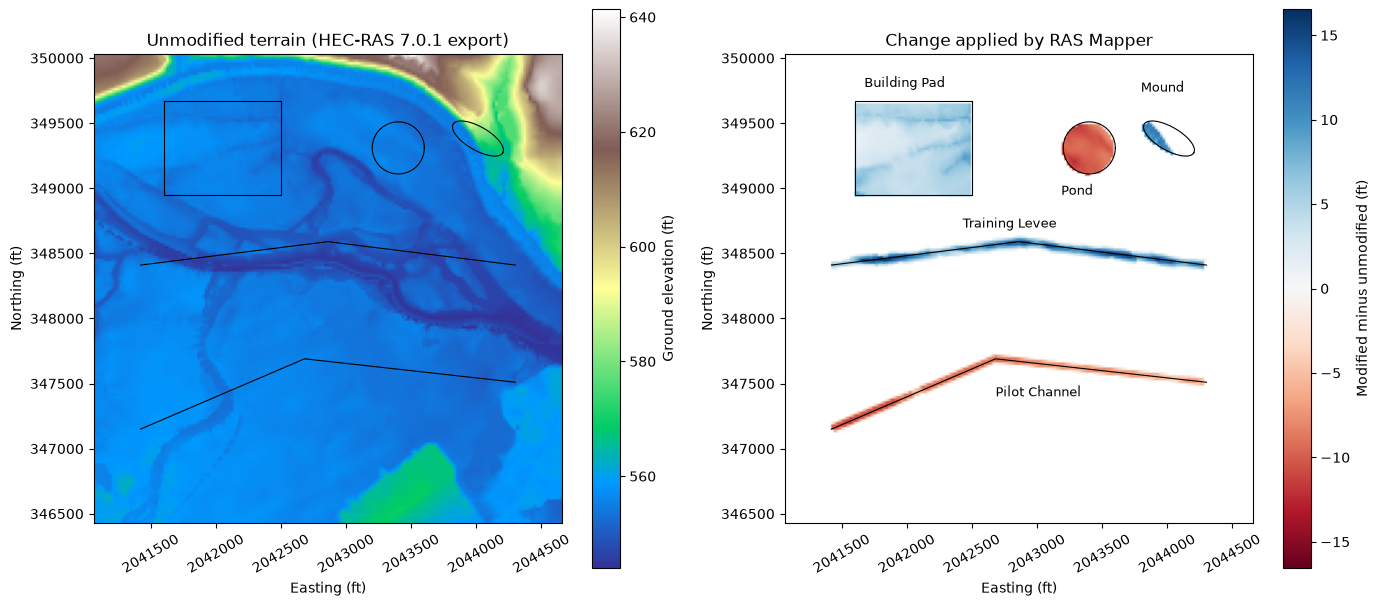

In [10]:
change = np.ma.masked_equal(on - off, 0.0)
extent = (X0, X0 + SIZE, Y0, Y0 + SIZE)
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
ground = axes[0].imshow(off, extent=extent, cmap="terrain")
fig.colorbar(ground, ax=axes[0], label="Ground elevation (ft)")
axes[0].set_title(f"Unmodified terrain (HEC-RAS {version} export)")
limit = float(np.nanmax(np.abs(change)))
diff = axes[1].imshow(change, extent=extent, cmap="RdBu", vmin=-limit, vmax=limit)
fig.colorbar(diff, ax=axes[1], label="Modified minus unmodified (ft)")
axes[1].set_title("Change applied by RAS Mapper")
for ax in axes:
    for geom in (channel, levee):
        ax.plot(*geom.xy, color="k", linewidth=0.8)
    for geom in (pad_poly, pond_poly, mound_poly):
        ax.plot(*geom.exterior.xy, color="k", linewidth=0.8)
    ax.set_xlabel("Easting (ft)")
    ax.set_ylabel("Northing (ft)")
    ax.ticklabel_format(useOffset=False, style="plain")
    ax.tick_params(axis="x", labelrotation=30)
for label, xy in (("Pilot Channel", site(0.45, 0.27)), ("Training Levee", site(0.38, 0.63)),
                  ("Building Pad", site(0.17, 0.93)), ("Pond", site(0.59, 0.70)),
                  ("Mound", site(0.76, 0.92))):
    axes[1].annotate(label, xy, fontsize=9)
plt.tight_layout()
plt.show()

## Notes and limits

- The writers follow the layout RAS Mapper 6.6 and 7.0.1 save: ground lines with an empty
  `System Name` (a named system takes RAS Mapper's system path, which changes the footprint),
  NaN `Transition Percent`, and unique layer priorities with the newest layer on top.
- `add_modification_layer` writes ground lines, constant polygons and ellipses. It refuses
  layers with control points, boundary-elevation polygons and shape-Z polygons, because it
  cannot store them so that RAS Mapper applies them the same way.
- HEC-RAS 6.6 skips a ground line whose Max Reach is not wider than one terrain cell; 7.0 and
  7.0.1 burn it in. The lines here are several cells wide.
- HEC-RAS 7.0.0 has a documented terrain-modification export defect. Use 7.0.1 or later.
- For analysis of modified terrain (profiles, elevation-volume curves), see
  [Terrain Modification Analysis](930_terrain_modification_analysis.ipynb). For hydraulic
  effects of written modifications, see [Terrain Modifications](316_terrain_modifications.ipynb).